# Model 5 — a convolutional network over the 8 × 8 board

Same data, split, seed, optimizer, learning rate, weight decay, loss and early stopping as the baseline. **The one change is that the network is told the board is a board.**

Every model so far receives 64 squares as an unordered list and has to learn from scratch that square 12 is next to square 13 but not to square 20. A convolution has that built in: the same 3 × 3 filter is applied at every square, so a pattern like "my pawn defended by my pawn" is learned once and recognised everywhere instead of being learned 64 times.

**Parameter-matched on purpose — 133,077 against the baseline's 132,969, 100.1%.** The hidden layer is 58 wide for exactly that reason, so a win is geometry rather than size. That is the same discipline `model3` used to make its 4.1% mean something.

## The cost, stated before the run rather than after

Two 3 × 3 convolutions over 8 × 8 is roughly **one million operations per evaluation**, against about **9,700** for the folded MLP that CW-236 describes. Two orders of magnitude, and it comes directly off search depth at a 200 ms budget. The folding trick does not survive either: there is no "accumulate over occupied squares" form of a convolution, so the C++ port would be a different and much larger job than CW-236 assumes.

So this run is a **measurement for the report** — "convolution bought X% and cost 100× per evaluation" is a real architectural finding, and comparing architectures is part of what the project is for. It is not assumed to be shippable. If it wins large, that is a new engine ticket and a conversation about the evaluation budget, not a drop-in replacement.

The encoder is untouched: `encode.py` still produces 64 categories and five binary inputs, and only this notebook's reading of them changes.

Artifacts: `model5.pt`, `model5_history.json`, `model5_val_predictions.csv`.

Run top to bottom from a fresh kernel. `final_test.csv` is never opened here.

In [1]:
import csv, json, time
import sys
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

# ml/ is the root whether the notebook is opened from ml/ or ml/notebooks/.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))

from canonical import MAX_CP
from encode import CATEGORIES, EMBED_DIM, FEATURES, INPUT_SIZE, SQUARES, encode
from targets import S, to_cp, to_target

DATA = ROOT / "data"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)

RUN = "model5"
PARENT = "model2"
BASELINE = "model2"
BASELINE_PARAMETERS = 132_969

# Twelve piece planes plus the five binary inputs broadcast as constant planes.
# The empty-square category is dropped: it is 1 - sum(the other twelve) at every
# square, so it is a plane the network can derive and costs 4,608 weights to
# hand over.
PIECE_PLANES = CATEGORIES - 1      # 12
PLANES = PIECE_PLANES + 5          # 17

torch.set_num_threads(4)
print(torch.__version__, "| run", RUN, f"| {PLANES} planes of 8x8")

2.14.1+cpu | run model5 | 17 planes of 8x8


## Experiment parameters

The baseline's, except for the architecture. `max_epochs` is lower because an epoch here costs several times what the MLP's does — with `patience` 6 the run is expected to stop well before the limit anyway, and a limit that would take two hours to reach is not a limit, it is an accident waiting to happen.

In [2]:
CONFIG = {
    "run": RUN,
    "parent": PARENT,
    "changed_from_baseline": "MLP -> 2-layer CNN over 8x8 planes (parameter-matched)",
    "seed": 20261001,
    "embed_dim": None,               # no embedding: one-hot planes
    "planes": PLANES,
    "channels": 32,
    "kernel": 3,
    "hidden": 58,                    # chosen to match the baseline's 132,969
    "batch_size": 1024,
    "lr": 1e-3,
    "weight_decay": 1e-4,
    "max_epochs": 40,
    "patience": 6,
    "optimizer": "AdamW",
    "loss": "MSE on asinh(cp / S)",
    "S": S,
}
CONFIG

{'run': 'model5',
 'parent': 'model2',
 'changed_from_baseline': 'MLP -> 2-layer CNN over 8x8 planes (parameter-matched)',
 'seed': 20261001,
 'embed_dim': None,
 'planes': 17,
 'channels': 32,
 'kernel': 3,
 'hidden': 58,
 'batch_size': 1024,
 'lr': 0.001,
 'weight_decay': 0.0001,
 'max_epochs': 40,
 'patience': 6,
 'optimizer': 'AdamW',
 'loss': 'MSE on asinh(cp / S)',
 'S': 1000}

## Dataset loading

Byte-identical to the baseline's. The stored tensors are the same 64 categories and five flags; the planes are built per batch inside the model, because 500,000 × 17 × 64 floats would be 2.2 GB where one batch is 4.5 MB.

In [3]:
def rows_of(split):
    """A split as (fen, target_value) pairs, in the file's own order.

    That order is (game_id, ply), inherited from the labeled file, so anything
    written back out alongside these rows lines up with the dataset.
    """
    with open(DATA / f"final_{split}.csv", newline="", encoding="utf-8") as fh:
        reader = csv.reader(fh)
        next(reader)                                   # fen,target_value
        return [(fen, int(target)) for fen, target in reader]


def load(rows):
    """Rows to tensors, encoded once up front.

    600,000 rows at 69 values is 41 MB as uint8, so the whole dataset lives in
    memory and every epoch after this is pure tensor arithmetic. Encoding inside
    the training loop would make a Python function call the bottleneck and hide
    what the model itself costs.
    """
    squares, flags, targets = [], [], []
    for fen, target in rows:
        position = encode(fen)
        squares.append(position.squares)
        flags.append((position.side_to_move,) + position.castling)
        # The one place centipawns become targets. Raw cp never enters a tensor,
        # so "loss is never computed on raw centipawns" holds by construction
        # rather than by remembering.
        targets.append(to_target(target))
    return (
        torch.from_numpy(np.array(squares, dtype=np.uint8)),
        torch.from_numpy(np.array(flags, dtype=np.float32)),
        torch.from_numpy(np.array(targets, dtype=np.float32)).unsqueeze(1),
    )


started = time.time()
train = load(rows_of("train"))       # the row list is not kept; only val's is
val_rows = rows_of("val")
val = load(val_rows)
# final_test.csv is deliberately not opened in this notebook. CW-164 froze it,
# and the simplest enforcement of that is its absence.
print(f"loaded and encoded in {time.time() - started:.0f}s")
print("train", tuple(train[0].shape), tuple(train[1].shape), tuple(train[2].shape))
print("val  ", tuple(val[0].shape), tuple(val[1].shape), tuple(val[2].shape))

loaded and encoded in 11s
train (500000, 64) (500000, 5) (500000, 1)
val   (50000, 64) (50000, 5) (50000, 1)


In [4]:
# Against the dataset's own measured numbers. A mate fraction far from 4.7% or a
# side-to-move split far from 49.8% would mean the encoder and the CSV disagree
# about what a row is — the one failure that would otherwise train quietly and
# evaluate nonsense.
squares, flags, targets = train
assert squares.shape[1] + flags.shape[1] == FEATURES == 69
assert 0 <= int(squares.min()) and int(squares.max()) < CATEGORIES
assert set(flags.unique().tolist()) <= {0.0, 1.0}

print(f"target  mean {targets.mean():+.4f}  std {targets.std():.4f}  "
      f"min {targets.min():+.4f}  max {targets.max():+.4f}")
median = float(targets.abs().median())
print(f"        median |target| {median:.4f}  ->  {to_cp(median):.0f} cp")
mates = (targets.abs() > to_target(MAX_CP)).float().mean()
print(f"mate band        {100 * mates:.1f}% of rows (expected 4.7%)")
print(f"White to move    {100 * flags[:, 0].mean():.1f}% (expected 49.8%)")

target  mean +0.0582  std 0.7998  min -3.0637  max +3.0637
        median |target| 0.2861  ->  290 cp
mate band        4.7% of rows (expected 4.7%)
White to move    49.8% (expected 49.8%)


## From 64 categories to 17 planes

`encode.py` numbers squares `8 * rank + file` with a1 = 0, so reshaping 64 to `(8, 8)` gives `[rank][file]` with rank 1 first. Getting that transposed would mirror or rotate every position — and the network would train perfectly happily on it, which is exactly why the next cell checks rather than assumes.

In [5]:
def planes_of(squares, flags):
    """(B, 64) categories and (B, 5) flags to (B, 17, 8, 8).

    The five scalars are broadcast to full planes rather than concatenated at
    the dense layer, so the convolutions can use them — whether a pawn push is
    good depends on whose move it is, and a filter that cannot see that has to
    learn both cases as one blur.
    """
    pieces = F.one_hot(squares.long(), CATEGORIES)[..., 1:]      # drop "empty"
    pieces = pieces.permute(0, 2, 1).reshape(-1, PIECE_PLANES, 8, 8).float()
    scalars = flags.view(-1, 5, 1, 1).expand(-1, 5, 8, 8)
    return torch.cat([pieces, scalars], dim=1)


# Three checks, because a wrong orientation is invisible in a loss curve.
sample = planes_of(val[0][:4], val[1][:4])
assert sample.shape == (4, PLANES, 8, 8)
assert torch.equal(sample[:, :PIECE_PLANES].sum((1, 2, 3)).long(),
                   (val[0][:4] > 0).sum(1).long())      # one plane per occupied square
assert torch.equal(sample[:, PIECE_PLANES], val[1][:4, 0].view(-1, 1, 1).expand(-1, 8, 8))

# And one to read: the first validation position, as occupancy, rank 8 at the top.
print(val_rows[0][0])
board = sample[0, :PIECE_PLANES].sum(0).int().flip(0)
for rank in board.tolist():
    print("   " + " ".join(".x"[v] for v in rank))

r2qk1nr/1pp2ppp/p1pb4/4p3/3PP1b1/4BN2/PPP2PPP/RN1QK2R b KQkq - 0 7
   x . . x x . x x
   . x x . . x x x
   x . x x . . . .
   . . . . x . . .
   . . . x x . x .
   . . . . x x . .
   x x x . . x x x
   x x . x x . . x


## Model architecture

| layer | output | parameters |
|---|---|---|
| `Conv2d(17, 32, 3, padding=1)` + ReLU | (B, 32, 8, 8) | 4,928 |
| `Conv2d(32, 32, 3, padding=1)` + ReLU | (B, 32, 8, 8) | 9,248 |
| flatten | (B, 2048) | — |
| `Linear(2048, 58)` + ReLU | (B, 58) | 118,842 |
| `Linear(58, 1)` | (B, 1) | 59 |
| | **total** | **133,077** |

`padding=1` keeps the board 8 × 8 throughout — no pooling, because there is no sense in which half a chessboard is a summary of it, and 8 × 8 is small enough that nothing needs downsampling. Two convolutions give each output square a 5 × 5 receptive field; the dense layer is what finally sees the whole board, which is also where most of the parameters are.

In [6]:
class Model5(nn.Module):
    """Two 3x3 convolutions over 17 planes, then a dense layer to one output.

    The output carries no activation. Evaluations are signed, and the target
    spans roughly -3.06 to +3.06 after the asinh transform.
    """

    def __init__(self, channels=CONFIG["channels"], hidden=CONFIG["hidden"],
                 kernel=CONFIG["kernel"]):
        super().__init__()
        pad = kernel // 2
        self.conv1 = nn.Conv2d(PLANES, channels, kernel, padding=pad)
        self.conv2 = nn.Conv2d(channels, channels, kernel, padding=pad)
        self.hidden = nn.Linear(channels * SQUARES, hidden)
        self.out = nn.Linear(hidden, 1)
        # Kaiming with the ReLU gain on every layer that feeds one — the same
        # rule the MLPs use, and it matters more here because the shrinkage of
        # PyTorch's default compounds across three layers.
        for layer in (self.conv1, self.conv2, self.hidden):
            nn.init.kaiming_uniform_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)

    def forward(self, squares, flags):
        x = planes_of(squares, flags)
        x = torch.relu(self.conv1(x))
        x = torch.relu(self.conv2(x))
        x = torch.relu(self.hidden(x.flatten(1)))
        return self.out(x)


torch.manual_seed(CONFIG["seed"])
model = Model5()

parameters = sum(p.numel() for p in model.parameters())
CONFIG["parameters"] = parameters
print(model)
print(f"\n{parameters:,} parameters — "
      f"{100 * parameters / BASELINE_PARAMETERS:.1f}% of the baseline's "
      f"{BASELINE_PARAMETERS:,}")
print(f"{len(train[0]) / parameters:.1f} training rows each (the baseline has 3.8)")

# What it costs to evaluate one position, which is the number that decides
# whether this architecture could ever sit inside the search (CW-236).
conv = PLANES * CONFIG["channels"] * 9 * SQUARES + \
    CONFIG["channels"] ** 2 * 9 * SQUARES
dense = CONFIG["channels"] * SQUARES * CONFIG["hidden"]
print(f"\n~{conv + dense:,} multiply-accumulates per evaluation, against ~9,700 "
      f"for the folded MLP")

Model5(
  (conv1): Conv2d(17, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (hidden): Linear(in_features=2048, out_features=58, bias=True)
  (out): Linear(in_features=58, out_features=1, bias=True)
)

133,077 parameters — 100.1% of the baseline's 132,969
3.8 training rows each (the baseline has 3.8)

~1,021,952 multiply-accumulates per evaluation, against ~9,700 for the folded MLP


## Optimizer, loss, and the validation pass

Unchanged from the baseline, MSE included — `model2_run4` is testing the loss, and changing both here would leave neither attributable.

In [7]:
optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["lr"],
                              weight_decay=CONFIG["weight_decay"])
criterion = nn.MSELoss()


@torch.no_grad()
def evaluate(data, chunk=8192):
    """Mean squared error over a whole split, in transformed space."""
    model.eval()
    squares, flags, targets = data
    total = 0.0
    for i in range(0, len(squares), chunk):
        predicted = model(squares[i:i + chunk], flags[i:i + chunk])
        total += criterion(predicted, targets[i:i + chunk]).item() * len(predicted)
    return total / len(squares)


print(f"val loss at init  {evaluate(val):.4f}   (the baseline's was 0.7239)")
print(f"target variance   {val[2].var():.4f}")

val loss at init  0.6754   (the baseline's was 0.7239)
target variance   0.6350


## Training loop

Byte-identical to the baseline's. For reference: `model2` reached **0.25692 at epoch 10**, `model3` (two layers of 187, parameter-matched) **0.24644 at epoch 10**.

**Expect roughly 60–120 seconds an epoch**, against the MLP's 10 — the convolutions are about a hundred times the arithmetic per position. With `patience` 6 a stop somewhere near epoch 15–20 is likely, so budget 20–40 minutes rather than the two hours `max_epochs` would allow.

In [8]:
CHECKPOINT = MODELS / f"{RUN}.pt"
HISTORY = MODELS / f"{RUN}_history.json"

generator = torch.Generator().manual_seed(CONFIG["seed"])
squares, flags, targets = train
n, batch = len(squares), CONFIG["batch_size"]

history, best, best_epoch = [], float("inf"), 0
started = time.time()

for epoch in range(1, CONFIG["max_epochs"] + 1):
    model.train()
    # Seeded shuffle, so the run reproduces from the dataset files alone.
    order = torch.randperm(n, generator=generator)
    running = 0.0
    for i in range(0, n, batch):
        index = order[i:i + batch]
        optimizer.zero_grad()
        loss = criterion(model(squares[index], flags[index]), targets[index])
        loss.backward()
        optimizer.step()
        running += loss.item() * len(index)

    train_loss, val_loss = running / n, evaluate(val)
    history.append({"epoch": epoch, "train": train_loss, "val": val_loss})
    marker = ""

    if val_loss < best:
        best, best_epoch, marker = val_loss, epoch, "  <- best"
        torch.save({"state_dict": model.state_dict(), "config": CONFIG,
                    "epoch": epoch, "val_loss": val_loss}, CHECKPOINT)

    print(f"epoch {epoch:3}  train {train_loss:.5f}  val {val_loss:.5f}"
          f"  {time.time() - started:5.0f}s{marker}")

    if epoch - best_epoch >= CONFIG["patience"]:
        print(f"\nstopping: no improvement in {CONFIG['patience']} epochs")
        break

HISTORY.write_text(json.dumps({"config": CONFIG, "best_epoch": best_epoch,
                               "best_val": best, "history": history}, indent=2))
print(f"\nbest val {best:.5f} at epoch {best_epoch} — saved to {CHECKPOINT.name}")

epoch   1  train 0.42371  val 0.30894     33s  <- best
epoch   2  train 0.28073  val 0.31051     67s
epoch   3  train 0.26165  val 0.26497    101s  <- best
epoch   4  train 0.25187  val 0.25348    134s  <- best
epoch   5  train 0.24828  val 0.25348    169s
epoch   6  train 0.24096  val 0.24687    203s  <- best
epoch   7  train 0.23763  val 0.24750    241s
epoch   8  train 0.23364  val 0.24874    274s
epoch   9  train 0.23020  val 0.24895    306s
epoch  10  train 0.22929  val 0.25239    336s
epoch  11  train 0.22647  val 0.25566    380s
epoch  12  train 0.22142  val 0.24112    421s  <- best
epoch  13  train 0.21919  val 0.24768    464s
epoch  14  train 0.21575  val 0.23598    503s  <- best
epoch  15  train 0.21410  val 0.24236    540s
epoch  16  train 0.21164  val 0.23752    579s
epoch  17  train 0.20948  val 0.25383    617s
epoch  18  train 0.20685  val 0.23680    663s
epoch  19  train 0.20490  val 0.23679    713s
epoch  20  train 0.20161  val 0.23759    766s

stopping: no improvement 

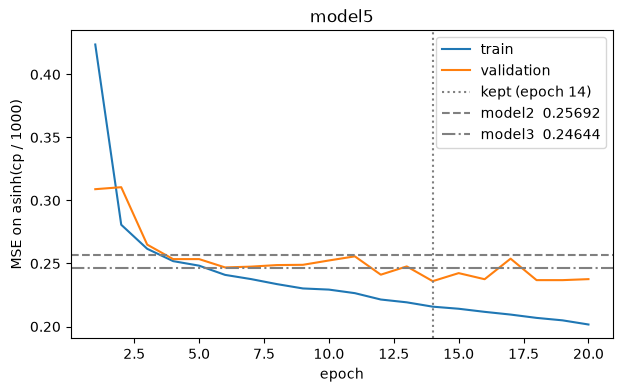

In [9]:
import matplotlib.pyplot as plt

epochs = [h["epoch"] for h in history]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs, [h["train"] for h in history], label="train")
ax.plot(epochs, [h["val"] for h in history], label="validation")
ax.axvline(best_epoch, color="grey", linestyle=":",
           label=f"kept (epoch {best_epoch})")
ax.axhline(0.25692, color="grey", linestyle="--", label="model2  0.25692")
ax.axhline(0.24644, color="grey", linestyle="-.", label="model3  0.24644")
ax.set(xlabel="epoch", ylabel="MSE on asinh(cp / 1000)", title=RUN)
ax.legend()
plt.show()

## Validation error in centipawns

The baseline: median **173.9** cp, mean **618.1** cp, sign disagreement **23.2%**. These are loss-independent, so they compare across every run without an asterisk.

In [10]:
model.load_state_dict(torch.load(CHECKPOINT, weights_only=True)["state_dict"])
model.eval()
with torch.no_grad():
    predicted = torch.cat([model(val[0][i:i + 8192], val[1][i:i + 8192])
                           for i in range(0, len(val[0]), 8192)])

predicted_cp = S * torch.sinh(predicted.squeeze(1))
actual_cp = S * torch.sinh(val[2].squeeze(1))
error = (predicted_cp - actual_cp).abs()

print(f"median absolute error  {error.median():8.1f} cp   (baseline 173.9)")
print(f"mean   absolute error  {error.mean():8.1f} cp   (baseline 618.1)")
disagree = ((predicted_cp > 0) != (actual_cp > 0)).float().mean()
print(f"sign disagreement      {100 * disagree:8.1f}%   (baseline 23.2)")

median absolute error     163.8 cp   (baseline 173.9)
mean   absolute error     598.8 cp   (baseline 618.1)
sign disagreement          20.8%   (baseline 23.2)


In [11]:
# Bucketed by the magnitude of the true evaluation. The 0-300 band is where games
# are decided and where classification.js's thresholds live, so it is the band
# the eval bar and the feedback feature actually depend on.
#
# The baseline's numbers, for each row below:
#   mate rows        2,347 (4.7%)   median 8389.4   sign  6.6%
#   cp rows only    47,653 (95.3%)  median  161.2   sign 24.0%
#   |actual| < 100  16,637 (33.3%)  median   74.5   sign 41.5%
#   100 - 300        9,038 (18.1%)  median  126.8   sign 26.1%
#   300 - 1000      20,042 (40.1%)  median  299.8   sign 10.6%
#   above 1000       1,936 ( 3.9%)  median  619.8   sign  2.2%
is_mate = actual_cp.abs() > MAX_CP


def report(label, mask):
    if not mask.any():
        return
    chosen = error[mask]
    wrong = ((predicted_cp[mask] > 0) != (actual_cp[mask] > 0)).float().mean()
    print(f"{label:16} n {int(mask.sum()):6,} ({100 * mask.float().mean():4.1f}%)  "
          f"median {chosen.median():7.1f}  mean {chosen.mean():8.1f}  "
          f"sign {100 * wrong:5.1f}%")


report("mate rows", is_mate)
report("cp rows only", ~is_mate)
print()
for low, high, label in [(0, 100, "|actual| < 100"), (100, 300, "100 - 300"),
                         (300, 1000, "300 - 1000"), (1000, 10 ** 9, "above 1000")]:
    report(label, ~is_mate & (actual_cp.abs() >= low) & (actual_cp.abs() < high))

share = error[is_mate].sum() / error.sum()
print(f"\nthe mate rows carry {100 * share:.0f}% of the total absolute error "
      f"(baseline 58%)")

mate rows        n  2,347 ( 4.7%)  median  8199.1  mean   7421.9  sign   4.5%
cp rows only     n 47,653 (95.3%)  median   151.3  mean    262.8  sign  21.6%

|actual| < 100   n 16,637 (33.3%)  median    63.8  mean    115.6  sign  37.8%
100 - 300        n  9,064 (18.1%)  median   118.6  mean    161.3  sign  22.5%
300 - 1000       n 20,016 (40.0%)  median   297.5  mean    371.6  sign   9.7%
above 1000       n  1,936 ( 3.9%)  median   547.8  mean    877.2  sign   1.9%

the mate rows carry 58% of the total absolute error (baseline 58%)


## Real against predicted, one row per validation position

`actual_cp` is the dataset's `target_value`, taken from the CSV as the integer it is rather than round-tripped through the transform, so the comparison carries none of our own arithmetic. For the 4.7% of rows that are mates, that value is the mate-band encoding (10,010 to 10,680) rather than a centipawn score the engine reported — hence `is_mate`, which is the column to filter on before reading any average.

In [ ]:
PREDICTIONS = MODELS / f"{RUN}_val_predictions.csv"

# load() preserved the order it was given and the predictions were built by
# walking the tensors in order, so row i of each is the same position. The
# assert is here because a silent misalignment would look like a badly trained
# model rather than like a bug.
assert len(val_rows) == len(predicted_cp)

with open(PREDICTIONS, "w", newline="", encoding="utf-8") as fh:
    writer = csv.writer(fh)
    writer.writerow(("fen", "actual_cp", "predicted_cp", "error_cp", "is_mate"))
    for (fen, actual), prediction in zip(val_rows, predicted_cp.tolist()):
        writer.writerow((fen, actual, round(prediction, 1),
                         round(prediction - actual, 1),
                         int(abs(actual) > MAX_CP)))

print(f"{len(val_rows):,} rows -> {PREDICTIONS}  "
      f"({PREDICTIONS.stat().st_size / 1e6:.1f} MB)")
with open(PREDICTIONS, encoding="utf-8") as fh:
    for _ in range(4):
        print("  " + next(fh).rstrip())

## Every run so far

Reads the history files, not the notebooks, so no other run is touched or re-run. Ranked on validation MSE, which every run has — the MSE-trained ones because it is what they optimised, the Huber run because it records it alongside. The `loss` column says which is which.

Read the `params` column beside the result: `model3` and `model5` are parameter-matched to the baseline and their deltas are architecture; `model2_run3` (embed_dim 16) and `model4` (one-hot) are not, and theirs are architecture plus size.

In [ ]:
runs = {path.name.replace("_history.json", ""): json.loads(path.read_text())
        for path in sorted(MODELS.glob("*_history.json"))}


def common(entry):
    """Validation MSE, whatever the run was trained on. Older histories predate
    the extra column, and for those best_val IS the MSE."""
    return entry.get("best_val_mse", entry["best_val"])


base = common(runs[BASELINE])
print(f"{'run':16} {'val MSE':>9}  {'epoch':>5}  {'params':>8}  "
      f"{'vs model2':>10}   {'loss':<7} changed")
for name, entry in sorted(runs.items(), key=lambda kv: common(kv[1])):
    config = entry["config"]
    loss = "Huber" if "SmoothL1" in config.get("loss", "") else "MSE"
    print(f"{name:16} {common(entry):9.5f}  {entry['best_epoch']:5}  "
          f"{config.get('parameters', 0):8,}  {common(entry) - base:+10.5f}   "
          f"{loss:<7} {config.get('changed_from_baseline') or '—'}")

fig, ax = plt.subplots(figsize=(7, 4))
for name, entry in runs.items():
    ax.plot([h["epoch"] for h in entry["history"]],
            [h.get("val_mse", h["val"]) for h in entry["history"]],
            label=name, linewidth=2 if name == RUN else 1,
            linestyle="-" if name in (RUN, BASELINE) else "--")
ax.set(xlabel="epoch", ylabel="MSE on asinh(cp / 1000)",
       title="validation MSE, every run")
ax.legend()
plt.show()